# 11. Load CSV Data

This tutorial provides examples of how to use CSV data with TensorFlow.

There are two main parts to this:

1. **Loading the data off disk**

2. **Pre-processing it into a form suitable for training.**

This tutorial focuses on the loading, and gives some quick examples of preprocessing. To learn more about the preprocessing aspect, check out the Working with preprocessing layers guide and the Classify structured data using Keras preprocessing layers tutorial.

### Setup

In [5]:
import pandas as pd
import numpy as np

# Make numpy values easier to read.
np.set_printoptions(precision=3, suppress=True)

import tensorflow as tf
from tensorflow.keras import layers

### In Memory Data

For any small CSV dataset the simplest way to train a TensorFlow model on it is to load into memory as a pandas `DataFrame` or a NumPy array.

A relatively simple example is the abalone dataset.

* The dataset is small.
* All the input features are limited-range floating point values.

Here is how to download the data into a `DataFrame`:

In [2]:
abalone_train = pd.read_csv(
    "https://storage.googleapis.com/download.tensorflow.org/data/abalone_train.csv",
    names=["Length", "Diameter", "Height", "Whole weight", "Shucked weight", "Viscera weight", "Shell weight", "Age"])

In [4]:
abalone_train.head()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
0,0.435,0.335,0.110,0.334,0.1355,0.0775,0.0965,7
1,0.585,0.450,0.125,0.874,0.3545,0.2075,0.2250,6
2,0.655,0.510,0.160,1.092,0.3960,0.2825,0.3700,14
3,0.545,0.425,0.125,0.768,0.2940,0.1495,0.2600,16
4,0.545,0.420,0.130,0.879,0.3740,0.1695,0.2300,13


In [5]:
abalone_train.shape

(3320, 8)

The dataset contains a set of measurements of abalone, a type of sea snail.

The nominal task for this dataset is to predict the age from the other measurements, so separate the features and labels for training:

In [6]:
abalone_features = abalone_train.copy()
abalone_labels = abalone_features.pop('Age')

For this dataset, you will treat all features identically. Pack the features into a single NumPy array:

In [8]:
abalone_features = np.array(abalone_features)
abalone_features

array([[0.435, 0.335, 0.11 , ..., 0.136, 0.077, 0.097],
       [0.585, 0.45 , 0.125, ..., 0.354, 0.207, 0.225],
       [0.655, 0.51 , 0.16 , ..., 0.396, 0.282, 0.37 ],
       ...,
       [0.53 , 0.42 , 0.13 , ..., 0.374, 0.167, 0.249],
       [0.395, 0.315, 0.105, ..., 0.118, 0.091, 0.119],
       [0.45 , 0.355, 0.12 , ..., 0.115, 0.067, 0.16 ]], shape=(3320, 7))

Next, make a regression model predict the age. Since there is only a single input tensor, a `tf.keras.Sequential` model is sufficient here.

In [9]:
abalone_model = tf.keras.Sequential([
    layers.Dense(64, activation='relu'),
    layers.Dense(1)
])

abalone_model.compile(loss = tf.keras.losses.MeanSquaredError(),
                      optimizer = tf.keras.optimizers.Adam())

To train that model, pass the features and labels to `Model.fit`:

In [10]:
abalone_model.fit(abalone_features, abalone_labels, epochs=10)

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 82.3981
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 23.9102
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.8444
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.3305
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.9257
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.5509
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.2228
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6.9645
Epoch 9/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6.7634
Epoch 10/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6.6196


You have just seen the most basic way to train a model using CSV data. Next, you will learn how to apply preprocessing to normalize numeric columns.

### Basic Preprocessing

It's good practice to normalize the inputs to your model. The Keras preprocessing layers provide a convenient way to build this normalization into your model.

The `tf.keras.layers.Normalization` layer precomputes the mean and variance of each column, and uses these to normalize the data.

First, create the layer:

In [11]:
normalize = layers.Normalization()

Then, use the `Normalization.adapt` method to adapt the normalization layer to your data.

**Note:** Only use your training data with the `PreprocessingLayer.adapt` method. Do not use your validation or test data.

In [12]:
normalize.adapt(abalone_features)

Then, use the normalization layer in your model.

In [14]:
norm_abalone_model = tf.keras.Sequential([
    normalize,
    layers.Dense(64, activation='relu'),
    layers.Dense(1)
])

norm_abalone_model.compile(loss = tf.keras.losses.MeanSquaredError(),
                           optimizer = tf.keras.optimizers.Adam())

norm_abalone_model.fit(abalone_features, abalone_labels, epochs=10)

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 76.0716
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 38.0556
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 28.1528
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 18.7334
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 10.7160
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.3489
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6.4482
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6.0679
Epoch 9/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.8154
Epoch 10/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.5913


### Mixed Data Types

In the previous section, you worked with a dataset where all the features were limited-range floating point values. But not all datasets are limited to a single data type.

The "Titanic" dataset contains information about the passengers on the Titanic. The nominal task on this dataset is to predict who survived.

The raw data can easily be loaded as a Pandas `DataFrame`, but is not immediately usable as input to a TensorFlow model.

In [26]:
titanic = pd.read_csv("https://storage.googleapis.com/tf-datasets/titanic/train.csv")

HTTPError: HTTP Error 403: Forbidden

In [23]:
import tensorflow_datasets as tfds

ds = tfds.load('titanic', split='train', as_supervised=True)

In [27]:
ds

<_PrefetchDataset element_spec=({'age': TensorSpec(shape=(), dtype=tf.float32, name=None), 'boat': TensorSpec(shape=(), dtype=tf.string, name=None), 'body': TensorSpec(shape=(), dtype=tf.int32, name=None), 'cabin': TensorSpec(shape=(), dtype=tf.string, name=None), 'embarked': TensorSpec(shape=(), dtype=tf.int64, name=None), 'fare': TensorSpec(shape=(), dtype=tf.float32, name=None), 'home.dest': TensorSpec(shape=(), dtype=tf.string, name=None), 'name': TensorSpec(shape=(), dtype=tf.string, name=None), 'parch': TensorSpec(shape=(), dtype=tf.int32, name=None), 'pclass': TensorSpec(shape=(), dtype=tf.int64, name=None), 'sex': TensorSpec(shape=(), dtype=tf.int64, name=None), 'sibsp': TensorSpec(shape=(), dtype=tf.int32, name=None), 'ticket': TensorSpec(shape=(), dtype=tf.string, name=None)}, TensorSpec(shape=(), dtype=tf.int64, name=None))>

In [28]:
titanic_features = titanic.copy()
titanic_labels = titanic_features.pop('survived')

AttributeError: '_PrefetchDataset' object has no attribute 'copy'

Because of the different data types and ranges, you can't simply stack the features into a NumPy array and pass it to a `tf.keras.Sequential()` model. Each column needs to be handled individually.

As one option, you could preprocess your data offline (using any tool you like) to convert categorical columns to numeric columns, then pass the processed output to your TensorFlow model. The disadvantage to that approach is that if you save and export your model the preprocessing is not saved with it. The Keras preprocessing layers avoid this problem because they're part of the model.

In this example, you'll build a model that implements the preprocessing logic using Keras functional API. You could also do it by subclassing.

The functional API operates on "symbolic" tensors. Normal "eager" tensors have a value. In contrast these "symbolic" tensors do not. Instead they keep track of which operations are run on them, and build a representation of the calculation, that you can run later. Here's a quick example:

In [29]:
# Create a symbolic input
input = tf.keras.Input(shape=(), dtype=tf.float32)

# Perform a calculation using the input
result = 2 * input + 1

# The result doesn't have a value
result

<KerasTensor shape=(None,), dtype=float32, sparse=False, ragged=False, name=keras_tensor_9>

In [30]:
calc = tf.keras.Model(inputs=input, outputs=result)

In [31]:
print(calc(np.array([1])).numpy())
print(calc(np.array([2])).numpy())

[3.]
[5.]


To build the preprocessing model, start by building a set of symbolic `tf.keras.Input` objects, matching the names and data-types of the CSV columns.

In [32]:
inputs = {}

for name, column in titanic_features.items():
    dtype = column.dtype
    if dtype == object:
        dtype = tf.string
    else:
        dtype = tf.float32

    inputs[name] = tf.keras.Input(shape=(1,), name=name, dtype=dtype)

inputs

NameError: name 'titanic_features' is not defined

```
{'sex': <KerasTensor shape=(None, 1), dtype=string, sparse=False, name=sex>,
 'age': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, name=age>,
 'n_siblings_spouses': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, name=n_siblingsspouses>,
 'parch': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, name=parch>,
 'fare': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, name=fare>,
 'class': <KerasTensor shape=(None, 1), dtype=string, sparse=False, name=class>,
 'deck': <KerasTensor shape=(None, 1), dtype=string, sparse=False, name=deck>,
 'embark_town': <KerasTensor shape=(None, 1), dtype=string, sparse=False, name=embark_town>,
 'alone': <KerasTensor shape=(None, 1), dtype=string, sparse=False, name=along>}
```

The first step in your preprocessing logic is to concatenate the numeric inputs together, and run them through a normalization layer:

In [33]:
numeric_inputs = {name: input for name, input in inputs.items() if input.dtype == tf.float32}

x = layers.Concatenate()(list(numeric_inputs.values()))
norm = layers.Normalization()
norm.adapt(np.array(titanic[numeric_inputs.keys()]))
all_numeric_inputs = norm(x)

all_numeric_inputs

TypeError: object of type 'NoneType' has no len()

`<KerasTensor shape=(None, 4), dtype=float32, sparse=False, name=keras_tensor_11>`

Collect all the symbolic preprocessing results, to concatenate them later:

In [34]:
preprocessed_inputs = [all_numeric_inputs]

NameError: name 'all_numeric_inputs' is not defined

For the string inputs use the `tf.keras.layers.StringLookup` function to map strings to integer indices in a vocabulary. Next, use `tf.keras.layers.CategoryEncoding` to convert the indexes into `float32` data appropriate for the model.

The default settings for the `tf.keras.layers.CategoryEncoding` layer create a one-hot vector for each input. A `tf.keras.layers.Embedding` would also work. Check out the Working with preprocessing layers guide and the Classify structured data using Keras preprocessing layers tutorial for more on this topic.

In [35]:
for name, input in inputs.items():
    if input.dtype == tf.float32:
        continue

    lookup = layers.StringLookup(vocabulary=np.unique(titanic_features[name]))
    one_hot = layers.CategoryEncoding(num_tokens=lookup.vocabulary_size())

    x = lookup(input)
    x = one_hot(x)
    preprocessed_inputs.append(x)

With the collection of `inputs` and `preprocessed_inputs`, you can concatenate all the preprocessed inputs together, and build a model that handles the preprocessing:

In [37]:
preprocessed_inputs_cat = layers.Concatenate()(preprocessed_inputs)

titanic_preprocessing = tf.keras.Model(inputs, preprocessed_inputs_cat)

tf.keras.utils.plot_model(model = titanic_preprocessing, rankdir='LR', dpi=72, show_shapes=True)

NameError: name 'preprocessed_inputs' is not defined

The model just contains the input preprocessing. You can run it to see what it does to your data. Keras models don't automatically convert pandas `DataFrame`s because it's not clear if it should be converted to one tensor or to a dictionary of tensors. So, convert it to a dictionary of tensors:

In [38]:
titanic_features_dict = {name: np.array(value)
                         for name, value in titanic_features.items()}

NameError: name 'titanic_features' is not defined

Slice out the first training example and pass it to this preprocessing model, you see the numeric features and string one-hots all concatenated together:

In [40]:
features_dict = {name:values[:1] for name, values in titanic_features_dict.items()}
titanic_preprocessing(features_dict)

NameError: name 'titanic_features_dict' is not defined

```
<tf.Tensor: shape=(1, 28), dtype=float32, numpy=
array=([[-0.61 ,  0.395, -0.479, -0.497,  0.   ,  0.   ,  1.   ,  0.   ,

          0.   ,  0.   ,  1.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
          0.   ,  0.   ,  0.   ,  1.   ,  0.   ,  0.   ,  0.   ,  1.   ,
          0.   ,  0.   ,  1.   ,  0.   ]], dtype=float32)>
```

Now, build the model on top of this:

In [41]:
def titanic_model(preprocessing_head, inputs):
    body = tf.keras.Sequential([
        layers.Dense(64, activation='relu'),
        layers.Dense(1)
    ])

    preprocessed_inputs = preprocessing_head(inputs)
    result = body(preprocessed_inputs)
    model = tf.keras.Model(inputs, result)

    model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
                  optimizer=tf.keras.optimizers.Adam())
    return model

titanic_model = titanic_model(titanic_preprocessing, inputs)

NameError: name 'titanic_preprocessing' is not defined

When you train the model, pass the dictionary of features as `x`, and the label as `y`.

In [42]:
titanic_model.fit(x=titanic_features_dict, y=titanic_labels, epochs=10)

AttributeError: 'function' object has no attribute 'fit'

Since the preprocessing is part of the model, you can save the model and reload it somewhere else and get identical results:

In [43]:
titanic_model.save('test.keras')
reloaded = tf.keras.models.load_model('test.keras')

AttributeError: 'function' object has no attribute 'save'

In [44]:
features_dict = {name:values[:1] for name, values in titanic_features_dict.items()}

before = titanic_model(features_dict)
after = reloaded(features_dict)
assert (before-after) < 1e-3
print(before)
print(after)

NameError: name 'titanic_features_dict' is not defined

```
tf.Tensor([[-1.882]], shape=(1, 1), dtype=float32)
tf.Tensor([[-1.882]], shape=(1, 1), dtype=float32)
```

### Using tf.data

In the previous section you relied on the model's built-in data shuffling and batching while training the model.

If you need more control over the input data pipeline or need to use data that doesn't easily fit into memory: use `tf.data`.

For more examples, refer to the `tf.data`: Build TensorFlow input pipelines guide.

**On in memory data**

As a first example of applying `tf.data` to CSV data, consider the following code to manually slice up the dictionary of features from the previous section. For each index, it takes that index for each feature:

In [45]:
import itertools

def slices(features):
    for i in itertools.count():
        # For each feature take index 'i'
        example = {name:values[i] for name, values in features.items()}
        yield example

Run this and print the first example:

In [46]:
for example in slices(titanic_features_dict):
    for name, value in example.items():
        print(f"{name:19s}: {value}")
    break

NameError: name 'titanic_features_dict' is not defined

```
sex               : male
age               : 22.0
n_sibling_spouses : 1
parch             : 0
fare              : 7.25
class             : Third
deck              : unknown
embark_town       : Southampton
alone             : n
```

The mosty basic `tf.data.Dataset` in memory data loader is the `Dataset.from_tensor_slices` constructor. This returns a `tf.data.Dataset` that implements a generalized version of the above `slices` function, in TensorFlow.

In [47]:
features_ds = tf.data.Dataset.from_tensor_slices(titanic_features_dict)

NameError: name 'titanic_features_dict' is not defined

You can iterate over a `tf.data.Dataset` like any other python iterable:

In [48]:
for example in features_ds:
    for name, value in example.items():
        print(f"{name:19s}: {value}")
    break

NameError: name 'features_ds' is not defined

```
sex                : b'male'
age                : 22.0
n_siblings_spouses : 1
parch              : 0
fare               : 7.25
class              : b'Third'
deck               : b'unknown'
embark_town        : b'Southampton'
alone              : b'n'
```

The `from_tensor_slices` function can handle any structure of nested dictionaries or tuples. The following code makes a dataset of `(features_dict, labels)` pairs:

In [49]:
titanic_ds = tf.data.Dataset.from_tensor_slices((titanic_features_dict, titanic_labels))

NameError: name 'titanic_features_dict' is not defined

To train a model using this `Dataset`, you'll need to at least `shuffle` and `batch` the data.

In [50]:
titanic_batches = titanic_ds.shuffle(len(titanic_labels)).batch(32)

NameError: name 'titanic_ds' is not defined

Instead of passing `features` and `labels` to `Model.fit`, you pass the dataset:

In [51]:
titanic_model.fit(titanic_batches, epochs=5)

AttributeError: 'function' object has no attribute 'fit'

**From a single file**

So far this tutorial has worked with in-memory data. `tf.data` is a highly scalable toolkit for building data pipelines, and provides a few functions for loading CSV files.

In [52]:
titanic_file_path = tf.keras.utils.get_file("train.csv", "https://storage.googleapis.com/tf-datasets/titanic/train.csv")

Exception: URL fetch failure on https://storage.googleapis.com/tf-datasets/titanic/train.csv: 403 -- Forbidden

Now read the CSV data from the file and create a `tf.data.Dataset`.

(For the full documentation, see `tf.data.experimental.make_csv_dataset`)

In [53]:
titanic_csv_ds = tf.data.experimental.make_csv_dataset(
    titanic_file_path,
    batch_size=5,   # Artificially small to make examples easier to show
    label_name='survived',
    num_epochs=1,
    ignore_errors=True,)

NameError: name 'titanic_file_path' is not defined

This function includes many convenient features, so the data is easy to work with. This includes:

* Using the column headers as dictionary keys.
* Automaticcally determining the type of each column.

**Caution:** Make sure to set the `num_epochs` argument in `tf.data.experimental.make_csv_dataset`, otherwise the default behavior for `tf.data.Dataset` is to loop endlessly.

In [54]:
for batch, label in titanic_csv_ds.take(1):
    for key, value in batch.items():
        print(f"{key:20s}: {value}")
    print()
    print(f"{'label':20s}: {label}")

NameError: name 'titanic_csv_ds' is not defined

```
sex                 : [b'male' b'male' b'male' b'male' b'female']
age                 : [28. 28. 48. 61. 28.]
n_siblings_spouses  : [0 0 0 0 1]
parch               : [0 0 0 0 0]
fare                : [ 7.75   7.896 26.55  32.321 51.862]
class               : [b'Third' b'Third' b'First' b'First' b'First']
deck                : [b'unknown' b'unknown' b'E' b'D' b'D']
embark_town         : [b'Queenstown' b'Southampton' b'Southampton' b'Southampton' b'Southampton']
alone               : [b'y' b'y' b'y' b'y' b'n']

label               : [0 0 1 0 1]
```

**Note:** If you run the above cell twice it will produce different results. The default settings for `tf.data.experimental.make_csv_dataset` include `shuffle_buffer_size=1000`, which is more than sufficient for this small dataset, but may not be for a real-world dataset.

It can also decompress the data on the fly. Here's a gzipped CSV file containing the metro interstate traffic dataset.

In [55]:
traffic_volumn_csv_gz = tf.keras.utils.get_file(
    "Metro_Interstate_Traffic_Volumn.csv.gz",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz",
    cache_dir='.', cache_subdir='traffic')

 401408/Unknown 2s 5us/step

Set the `compression_type` argument to read directly from the compressed file:

In [58]:
traffic_volume_csv_gz_ds = tf.data.experimental.make_csv_dataset(
    traffic_volumn_csv_gz,
    batch_size=256,
    label_name='traffic_volume',
    num_epochs=1,
    compression_type="GZIP")

for batch, label in traffic_volume_csv_gz_ds.take(1):
    for key, value in batch.items():
        print(f"{key:20s}: {value[:5]}")
    print()
    print(f"{'label':20s}: {label[:5]}")

holiday             : [b'None' b'None' b'None' b'None' b'None']
temp                : [268.9  273.09 279.81 275.93 287.27]
rain_1h             : [0.   0.   0.   0.   0.25]
snow_1h             : [0. 0. 0. 0. 0.]
clouds_all          : [90 90  1 90 92]
weather_main        : [b'Mist' b'Snow' b'Clear' b'Drizzle' b'Rain']
weather_description : [b'mist' b'snow' b'sky is clear' b'light intensity drizzle' b'light rain']
date_time           : [b'2013-03-06 04:00:00' b'2013-04-12 06:00:00' b'2012-10-08 20:00:00'
 b'2013-01-12 17:00:00' b'2013-10-03 14:00:00']

label               : [ 792 5001 2378 4170 5272]


**Note:** If you need to parse those date-time strings in the `tf.data` pipeline, you can use `tfa.text.parse_time`.

**Caching**

There is some overhead to parsing the CSV data. For small models this can be the bottleneck in training.

Depending on your use case, it may be a good idea to use `Dataset.cache` or `tf.data.Dataset.snapshot`, so that the CSV data is only parsed on the first epoch.

The main difference between the `cache` and `snapshot` methods is that `cache` files can only be used by the TensorFlow process that created them, but `snapshot` files can be read by other processes.

For example, iterating over the `traffic_volumn_csv_gz_ds` 20 times may take around 15 seconds without caching, or about two seconds with caching.

In [61]:
%%time
for i, (batch, label) in enumerate(traffic_volume_csv_gz_ds.repeat(20)):
    if i % 40 == 0:
        print('.', end='')
print()

...............................................................................................
CPU times: total: 38.2 s
Wall time: 41.1 s


**Note:** `Dataset.cache` stores the data from the first epoch and replays it in order. So, using the `cache` method disables any shuffles earlier in the pipeline. Below, `Dataset.shuffle` is added back in after `Dataset.cache`.

In [63]:
%%time
caching = traffic_volume_csv_gz_ds.cache().shuffle(1000)

for i, (batch, label) in enumerate(caching.shuffle(1000).repeat(20)):
    if i % 40 == 0:
        print('.', end='')
print()

...............................................................................................
CPU times: total: 4.94 s
Wall time: 5.25 s


**Note:** The `tf.data.Dataset.snapshot` files are meant for temporary storage of a dataset while in use. This is not a format for long term storage. The file format is considered an internal detail, and not guaranteed between TensorFlow versions.

In [64]:
%%time
snapshotting = traffic_volume_csv_gz_ds.snapshot('titanic.tfsnap').shuffle(1000)

for i, (batch, label) in enumerate(snapshotting.shuffle(1000).repeat(20)):
    if i % 40 == 0:
        print('.', end='')
print()

...............................................................................................
CPU times: total: 8.58 s
Wall time: 6.1 s


If your data loading is slowed by loading CSV files, and `Dataset.cache` and `tf.data.Dataset.snapshot` are insufficient for your use case, consider re-encoding your data into a more streamlined format.

**Multiple files**

All the examples so far in this section could easily be done without `tf.data`. One place where `tf.data` can really simplify things is when dealing with collections of files.

For example, the character font images dataset is distributed as a collection of csv files, one per font.

Download the dataset, and review the files inside:

In [8]:
fonts_zip = tf.keras.utils.get_file(
    "fonts.zip", "https://archive.ics.uci.edu/ml/machine-learning-databases/00417/fonts.zip",
    cache_dir='.', cache_subdir='fonts',
    extract=True)

160309248/Unknown 158s 1us/step

In [12]:
import pathlib
font_csvs = sorted(str(p) for p in pathlib.Path('fonts/fonts_extracted').glob("*.csv"))

font_csvs[:10]

['fonts\\fonts_extracted\\AGENCY.csv',
 'fonts\\fonts_extracted\\ARIAL.csv',
 'fonts\\fonts_extracted\\BAITI.csv',
 'fonts\\fonts_extracted\\BANKGOTHIC.csv',
 'fonts\\fonts_extracted\\BASKERVILLE.csv',
 'fonts\\fonts_extracted\\BAUHAUS.csv',
 'fonts\\fonts_extracted\\BELL.csv',
 'fonts\\fonts_extracted\\BERLIN.csv',
 'fonts\\fonts_extracted\\BERNARD.csv',
 'fonts\\fonts_extracted\\BITSTREAMVERA.csv']

In [13]:
len(font_csvs)

153

When dealing with a bunch of files, you can pass a glob-style `file_pattern` to the `tf.data.experimental.make_csv_dataset` function. The order of the files is shuffled each iteration.

Use the `num_parallel_reads` argument to set how many files are read in parallel and interleaved together.

In [15]:
fonts_ds = tf.data.experimental.make_csv_dataset(
    file_pattern = "fonts/fonts_extracted/*.csv",
    batch_size=10, num_epochs=1,
    num_parallel_reads=20,
    shuffle_buffer_size=10000)

These CSV files have the images flattened out into a single row. The column names are formatted `r{row}c{column}`. Here's the first batch:

In [17]:
for features in fonts_ds.take(1):
    for i, (name, value) in enumerate(features.items()):
        if i > 15:
            break
        print(f"{name:20s}: {value}")
print("...")
print(f"[total: {len(features)} features]")

font                : [b'GABRIOLA' b'GIGI' b'BODONI' b'BODONI' b'PLAYBILL' b'TAI' b'MONEY'
 b'VERDANA' b'BLACKADDER' b'VERDANA']
fontVariant         : [b'GABRIOLA' b'GIGI' b'BODONI MT POSTER COMPRESSED'
 b'BODONI MT POSTER COMPRESSED' b'PLAYBILL' b'MICROSOFT TAI LE' b'scanned'
 b'VERDANA' b'BLACKADDER ITC' b'VERDANA']
m_label             : [ 964  243  109  713 8710  245   55  937  106  952]
strength            : [0.4 0.4 0.4 0.4 0.7 0.4 0.4 0.4 0.4 0.4]
italic              : [0 0 1 1 0 1 0 0 1 0]
orientation         : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
m_top               : [77 42 47 39 30 34  0 37 44 36]
m_left              : [21 23 20 33 20 27  0 23  4 24]
originalH           : [24 41 35  4 45 49 30 50 53 52]
originalW           : [20 21 37 16 42 40 19 49 47 34]
h                   : [20 20 20 20 20 20 20 20 20 20]
w                   : [20 20 20 20 20 20 20 20 20 20]
r0c0                : [1 1 1 0 1 1 1 1 1 1]
r0c1                : [ 43   1   1 192   1   1 242   1   1   1]
r0c2        

**Optional: Packing fields**

You probably don't want to work with each pixel in separate columns like this. Before trying to use this dataset be sure to pack the pixels into an image-tensor.

Here is code that parses the column names to build images for each example:

In [18]:
import re

def make_images(features):
    image = [None]*400
    new_feats = {}

    for name, value in features.items():
        match = re.match(r'(\d+)c(\d+)', name)
        if match:
            image[int(match.group(1))*20+int(match.group(2))] = value
        else:
            new_feats[name] = value

    image = tf.stack(image, axis=0)
    image = tf.reshape(image, [20, 20, -1])
    new_feats['image'] = image

    return new_feats

Apply that function to each batch in the dataset:

In [20]:
fonts_image_ds = fonts_ds.map(make_images)

for features in fonts_image_ds.take(1):
    break

ValueError: in user code:

    File "C:\Users\yigit\AppData\Local\Temp\ipykernel_24108\2587282295.py", line 14, in make_images  *
        image = tf.stack(image, axis=0)

    ValueError: None values not supported.


Plot the resulting images:

KeyError: 'image'

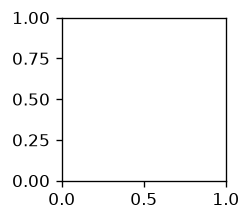

In [21]:
from matplotlib import pyplot as plt

plt.figure(figsize=(6,6), dpi=120)

for n in range(9):
    plt.subplot(3, 3, n+1)
    plt.imshow(features['image'][..., n])
    plt.title(chr(features['m_label'][n]))
    plt.axis('off')

### Lower Level Functions

So far this tutorial has focused on the highest-level utilities for reading csv data. There are two other APIs that amy be helpful for advanced uses if your use-case doesn't fit the basic patterns.

* `tf.io.decode_csv`: a function for parsing lines of text into a list of CSV column tensors.
* `tf.data.experimental.CsvDataset`: a lower-level CSV dataset constructor.

This section recreates functionality provided by `tf.data.experimental.make_csv_dataset`, to demonstrate how this lower-level functionality can be used.

**`tf.io.decode_csv`**

This function decodes a string, or list of strings into a list of columns.

Unlike `tf.data.experimental.make_csv_dataset` this function does not try to guess column data-types. You specify the column types by providing a list of `record_defaults` containing a value of the correct type, for each column.

To read the Titanic data **as strings** using `tf.io.decode_csv` you would say:

In [23]:
text = pathlib.Path(titanic_file_path).read_text()
lines = text.split('\n')[1:-1]

all_strings = [str()]*10
all_strings

NameError: name 'titanic_file_path' is not defined

`['', '', '', '', '', '', '', '', '', '']`

In [24]:
features = tf.io.decode_csv(lines, record_defaults=all_strings)

for f in features:
    print(f"type: {f.dtype.name}, shape: {f.shape}")

NameError: name 'lines' is not defined

```
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
```

To parse them with their actual types, create a list of `record_defaults` of the corresponding types:

In [25]:
print(lines[0])

NameError: name 'lines' is not defined

`0,male,22.0,1,0,7.25,Third,unknown,Southampton,n`

In [26]:
titanic_types = [int(), str(), float(), int(), int(), float(), str(), str(), str(), str()]
titanic_types

[0, '', 0.0, 0, 0, 0.0, '', '', '', '']

In [27]:
features = tf.io.decode_csv(lines, record_defaults=titanic_types)

for f in features:
    print(f"type: {f.dtype.name}, shape: {f.shape}")

NameError: name 'lines' is not defined

```
type: int32, shape: (627,)
type: string, shape: (627,)
type: float32, shape: (627,)
type: int32, shape: (627,)
type: int32, shape: (627,)
type: float32, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
type: string, shape: (627,)
```

**Note:** It is more efficient to call `tf.io.decode_csv` on large batches of lines than on individual lines of CSV text.

**`tf.data.experimental.CsvDataset`**

The `tf.data.experimental.CsvDataset` class provides a minimal CSV `Dataset` interface without the convenience features of the `tf.data.experimental.make_csv_dataset` function: column header parsing, column type-inference, automatic shuffling, file interleaving.

This constructor uses `record_defaults` the same way as `tf.io.decode_csv`:

In [29]:
simple_titanic = tf.data.experimental.CsvDataset(titanic_file_path, record_defaults=titanic_types, header=True)

for example in simple_titanic.take(1):
  print([e.numpy() for e in example])

NameError: name 'titanic_file_path' is not defined

`[0, b'male', 22.0, 1, 0, 7.25, b'Third', b'unknown', b'Southampton', b'n']`

The above code is basically equivalent to:

In [30]:
def decode_titanic_line(line):
    return tf.io.decode_csv(line, titanic_types)

manual_titanic = (
    # Load the lines of text
    tf.data.TextLineDataset(titanic_file_path)
    # Skip the header row
    .skip(1)
    # Decode the line
    .map(decode_titanic_line)
)

for example in manual_titanic.take(1):
    print([e.numpy() for e in example])

NameError: name 'titanic_file_path' is not defined

`[0, b'male', 22.0, 1, 0, 7.25, b'Third', b'unknown', b'Southampton', b'n']`

**Multiple files**

To parse the fonts dataset using `tf.data.experimental.CsvDataset`, you first need to determine the column types for the `record_defaults`. Start by inspecting the first row of one file:

In [31]:
font_line = pathlib.Path(font_csvs[0]).read_text().splitlines()[1]
print(font_line)

AGENCY,AGENCY FB,64258,0.400000,0,0.000000,35,21,51,22,20,20,1,1,1,21,101,210,255,255,255,255,255,255,255,255,255,255,255,255,255,255,1,1,1,93,255,255,255,176,146,146,146,146,146,146,146,146,216,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,141,141,141,182,255,255,255,172,141,141,141,115,1,1,1,1,163,255,255,255,255,255,255,255,255,255,255,255,255,255,255,209,1,1,1,1,163,255,255,255,6,6,6,96,255,255,255,74,6,6,6,5,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1,1,1,1,163,255,255,255,1,1,1,93,255,255,255,70,1,1,1,1,1

Only the first two fields are strings, the rest are integers or floats, and you can get the total number of features by counting the commas:

In [32]:
num_font_features = font_line.count(',')+1
font_column_types = [str(), str()] + [float()]*(num_font_features-2)

The `tf.data.experimental.CsvDataset` constructor can take a list of input files, but reads them sequentially. The first file in the list of CSVs is `AGENCY.csv`:

In [33]:
font_csvs[0]

'fonts\\fonts_extracted\\AGENCY.csv'

So, when you pass the list of files to `CsvDataset`, the records from `AGENCY.sys` are read first:

In [34]:
simple_font_ds = tf.data.experimental.CsvDataset(
    font_csvs, record_defaults=font_column_types, header=True)

In [35]:
for row in simple_font_ds.take(10):
    print(row[0].numpy())

b'AGENCY'
b'AGENCY'
b'AGENCY'
b'AGENCY'
b'AGENCY'
b'AGENCY'
b'AGENCY'
b'AGENCY'
b'AGENCY'
b'AGENCY'


To interleave multiple files, use `Dataset.interleave`.

Here's an initial dataset that contains the CSV file names:

In [37]:
font_files = tf.data.Dataset.list_files("fonts/fonts_extracted/*.csv")

This shuffles the file names each epoch:

In [38]:
print("Epoch 1:")
for f in list(font_files)[:5]:
    print("    ", f.numpy())
print("    ...")
print()

print("Epoch 2:")
for f in list(font_files)[:5]:
    print("    ", f.numpy())
print("    ...")

Epoch 1:
     b'fonts\\fonts_extracted\\CAMBRIA.csv'
     b'fonts\\fonts_extracted\\COMIC.csv'
     b'fonts\\fonts_extracted\\PMINGLIU-EXTB.csv'
     b'fonts\\fonts_extracted\\QUICKTYPE.csv'
     b'fonts\\fonts_extracted\\TECHNIC.csv'
    ...

Epoch 2:
     b'fonts\\fonts_extracted\\CANDARA.csv'
     b'fonts\\fonts_extracted\\GUNPLAY.csv'
     b'fonts\\fonts_extracted\\PLAYBILL.csv'
     b'fonts\\fonts_extracted\\TAI.csv'
     b'fonts\\fonts_extracted\\TAHOMA.csv'
    ...


The `interleave` method takes a `map_func` that creates a child-`Dataset` for each element of the parent-`Dataset`.

Here, you want to create a `tf.data.experimental.CsvDataset` from each element of the dataset of files:

In [39]:
def make_font_csv_ds(path):
    return tf.data.experimental.CsvDataset(path, record_defaults=font_column_types, header=True)

The `Dataset` returned by interleave returns elements by cycling over a number of the child-`Dataset`s. Note, below, how the dataset cycles over `cycle_length=3` three font files:

In [40]:
font_rows = font_files.interleave(make_font_csv_ds, cycle_length=3)

In [41]:
fonts_dict = {'font_name':[], 'character':[]}

for row in font_rows.take(10):
    fonts_dict['font_name'].append(row[0].numpy().decode())
    fonts_dict['character'].append(chr(int(row[2].numpy())))

pd.DataFrame(fonts_dict)

,font_name,character
0,CAMBRIA,︀
1,ROMANTIC,
2,MATURA,
3,CAMBRIA,ﬄ
4,ROMANTIC,
5,MATURA,
6,CAMBRIA,ﬃ
7,ROMANTIC,
8,MATURA,◊
9,CAMBRIA,ﬂ


**Performance**

Earlier, it was noted that `tf.io.decode_csv` is more efficient when run on a batch of strings.

It is possible to take advantage of this fact, when using large batch sizes, to improve CSV loading performance (but try caching first).

With the built-in loader 20, 2048-example batches take about 17s.

In [42]:
BATCH_SIZE=2048
fonts_ds = tf.data.experimental.make_csv_dataset(
    file_pattern="fonts/fonts_extracted/*.csv",
    batch_size=BATCH_SIZE, num_epochs=1,
    num_parallel_reads=100)

In [43]:
%%time
for i, batch in enumerate(fonts_ds.take(20)):
    print('.', end='')
print()

....................
CPU times: total: 1min 17s
Wall time: 45.6 s


Passing **batches of text lines** to `decode_csv` runs faster, in about 5s:

In [44]:
fonts_files = tf.data.Dataset.list_files("fonts/fonts_extracted/*.csv")
fonts_lines = fonts_files.interleave(
    lambda fname:tf.data.TextLineDataset(fname).skip(1),cycle_length=100).batch(BATCH_SIZE)

fonts_fast = fonts_lines.map(lambda x: tf.io.decode_csv(x, record_defaults=font_column_types))

In [45]:
%%time
for i, batch in enumerate(fonts_fast.take(20)):
    print('.', end='')
print()

....................
CPU times: total: 6.16 s
Wall time: 2.05 s


For another example of increasing CSV performance by using large batches, refer to the Overfit and underfit tutorial.

This sort of approach may work, but consider other options like `Dataset.cache` and `tf.data.Dataset.snapshot`, or re-encoding your data into a more streamlined format.